In [1]:
%pip install pandas numpy matplotlib seaborn scipy

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------ --------------------- 4.5/9.5 MB 23.3 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 30.9 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ------------------- -------------------- 18.6/37.4 MB 91.7 MB/s eta 0:00:01
   -------------------------- ------------- 25.2/37.4 MB 59.6 MB/s eta 0:00:01
   ------------------------------- -------- 29.4/37.4 MB 47.4 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 46.2 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 46.2 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 32.2 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 23.6 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("data_clean/football_metrics.csv")
df.head()

,CLUB,poss_pct,G,goals_per_match,xg_per_match,xg_per_shot,xg_per_100_passes
0,Arsenal,56.4,71,1.87,1.74,0.120,0.367
1,Aston Villa,53.7,56,1.47,1.28,0.100,0.283
2,Bournemouth,50.1,58,1.53,1.66,0.120,0.403
3,Brentford,47.4,55,1.45,1.58,0.148,0.401
4,Brighton,54.0,52,1.37,1.49,0.115,0.317


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CLUB               20 non-null     object 
 1   poss_pct           20 non-null     float64
 2   G                  20 non-null     int64  
 3   goals_per_match    20 non-null     float64
 4   xg_per_match       20 non-null     float64
 5   xg_per_shot        20 non-null     float64
 6   xg_per_100_passes  20 non-null     float64
dtypes: float64(5), int64(1), object(1)
memory usage: 1.2+ KB


In [5]:
df["CLUB"].duplicated().sum()

np.int64(0)

In [6]:
df.sort_values("xg_per_match", ascending=False).head()

,CLUB,poss_pct,G,goals_per_match,xg_per_match,xg_per_shot,xg_per_100_passes
12,Man City,60.6,77,2.03,1.87,0.119,0.320
6,Chelsea,57.7,58,1.53,1.76,0.131,0.327
0,Arsenal,56.4,71,1.87,1.74,0.120,0.367
13,Man United,51.9,69,1.82,1.70,0.109,0.367
2,Bournemouth,50.1,58,1.53,1.66,0.120,0.403


In [7]:
df.sort_values("xg_per_100_passes", ascending=False).head()

,CLUB,poss_pct,G,goals_per_match,xg_per_match,xg_per_shot,xg_per_100_passes
2,Bournemouth,50.1,58,1.53,1.66,0.120,0.403
3,Brentford,47.4,55,1.45,1.58,0.148,0.401
7,Crystal Palace,45.9,41,1.08,1.52,0.130,0.387
0,Arsenal,56.4,71,1.87,1.74,0.120,0.367
13,Man United,51.9,69,1.82,1.70,0.109,0.367


In [8]:
top5_xg = df.sort_values("xg_per_match", ascending=False).head()
top5_xg[["CLUB", "xg_per_match", "poss_pct"]]

,CLUB,xg_per_match,poss_pct
12,Man City,1.87,60.6
6,Chelsea,1.76,57.7
0,Arsenal,1.74,56.4
13,Man United,1.70,51.9
2,Bournemouth,1.66,50.1


In [9]:
top5_passes = df.sort_values("xg_per_100_passes", ascending=False).head()
top5_passes[["CLUB", "xg_per_100_passes", "poss_pct"]]

,CLUB,xg_per_100_passes,poss_pct
2,Bournemouth,0.403,50.1
3,Brentford,0.401,47.4
7,Crystal Palace,0.387,45.9
0,Arsenal,0.367,56.4
13,Man United,0.367,51.9


In [10]:
top5_passes = df.sort_values("xg_per_100_passes", ascending=False).head()
top5_passes = top5_passes[
    ["CLUB", "xg_per_match", "xg_per_100_passes", "poss_pct"]
].reset_index(drop=True)

top5_passes.index = range(1, 6)
top5_passes

,CLUB,xg_per_match,xg_per_100_passes,poss_pct
1,Bournemouth,1.66,0.403,50.1
2,Brentford,1.58,0.401,47.4
3,Crystal Palace,1.52,0.387,45.9
4,Arsenal,1.74,0.367,56.4
5,Man United,1.70,0.367,51.9


In [11]:
top5_xg = df.sort_values("xg_per_match", ascending=False).head()
top5_xg = top5_xg[
    ["CLUB", "xg_per_match", "xg_per_100_passes", "poss_pct"]
].reset_index(drop=True)

top5_xg.index = range(1, 6)
top5_xg

,CLUB,xg_per_match,xg_per_100_passes,poss_pct
1,Man City,1.87,0.320,60.6
2,Chelsea,1.76,0.327,57.7
3,Arsenal,1.74,0.367,56.4
4,Man United,1.70,0.367,51.9
5,Bournemouth,1.66,0.403,50.1


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

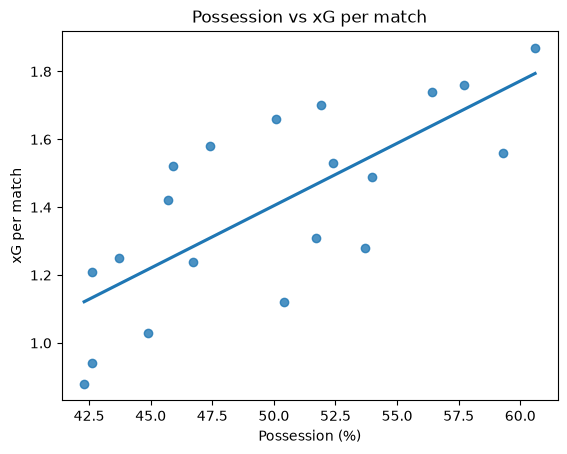

In [14]:
sns.regplot(data=df, x="poss_pct", y="xg_per_match", ci=None)
plt.title("Possession vs xG per match")
plt.xlabel("Possession (%)")
plt.ylabel("xG per match")
plt.show()

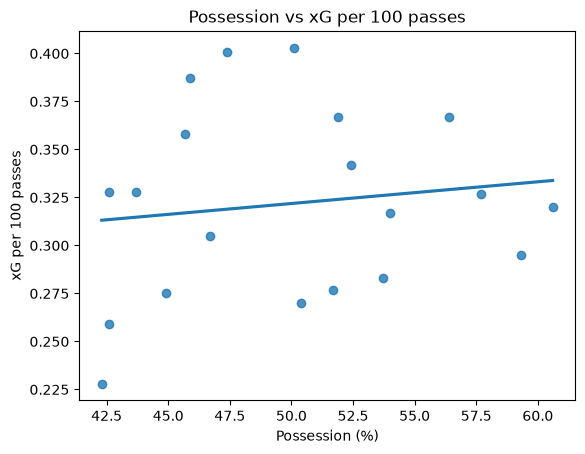

In [15]:
sns.regplot(data=df, x="poss_pct", y="xg_per_100_passes", ci=None)
plt.title("Possession vs xG per 100 passes")
plt.xlabel("Possession (%)")
plt.ylabel("xG per 100 passes")
plt.show()

In [5]:
r1 = df["poss_pct"].corr(df["xg_per_match"])
r2 = df["poss_pct"].corr(df["xg_per_100_passes"])

print("r1:", r1)
print("r2:", r2)

r1: 0.7461784495423364
r2: 0.1334258873204998


In [7]:
from scipy.stats import norm

n = len(df)
r12 = df["xg_per_match"].corr(df["xg_per_100_passes"])

k = r12 * (1 - r1**2 - r2**2) - 0.5*r1*r2*(1 - r1**2 - r2**2 - r12**2)
se = (((1 - r1**2)**2 + (1 - r2**2)**2 - 2*k) / n)**0.5

difference = r1 - r2
z = difference / se
p_value = norm.sf(z)

print("Διαφορά:", difference)
print("p-value:", format(p_value, ".8f"))

Διαφορά: 0.6127525622218366
p-value: 0.00008783


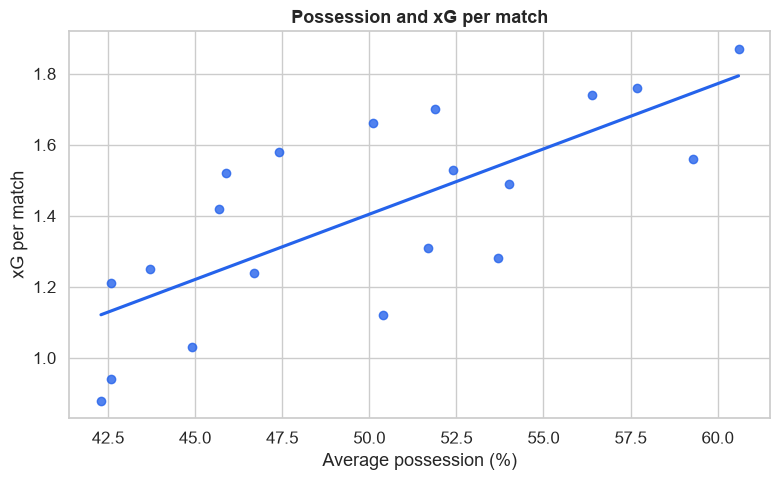

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid", font_scale=1.1)

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x="poss_pct",
    y="xg_per_match",
    ci=None,
    color="#2563EB"
)

plt.title("Possession and xG per match", fontweight="bold")
plt.xlabel("Average possession (%)")
plt.ylabel("xG per match")
plt.tight_layout()
plt.show()

In [10]:
top5_xg = df.nlargest(5, "xg_per_match")[["CLUB", "xg_per_match", "xg_per_100_passes", "poss_pct"]]

top5_xg.index = range(1, 6)

top5_xg.style.format(precision=3).background_gradient(subset=["xg_per_match"], cmap="Blues")

,CLUB,xg_per_match,xg_per_100_passes,poss_pct
1,Man City,1.870,0.320,60.600
2,Chelsea,1.760,0.327,57.700
3,Arsenal,1.740,0.367,56.400
4,Man United,1.700,0.367,51.900
5,Bournemouth,1.660,0.403,50.100


In [11]:
top5_passes = df.nlargest(5, "xg_per_100_passes")[["CLUB", "xg_per_match", "xg_per_100_passes", "poss_pct"]]

top5_passes.index = range(1, 6)

top5_passes.style.format(precision=3).background_gradient(subset=["xg_per_100_passes"], cmap="Blues")

,CLUB,xg_per_match,xg_per_100_passes,poss_pct
1,Bournemouth,1.660,0.403,50.100
2,Brentford,1.580,0.401,47.400
3,Crystal Palace,1.520,0.387,45.900
4,Arsenal,1.740,0.367,56.400
5,Man United,1.700,0.367,51.900


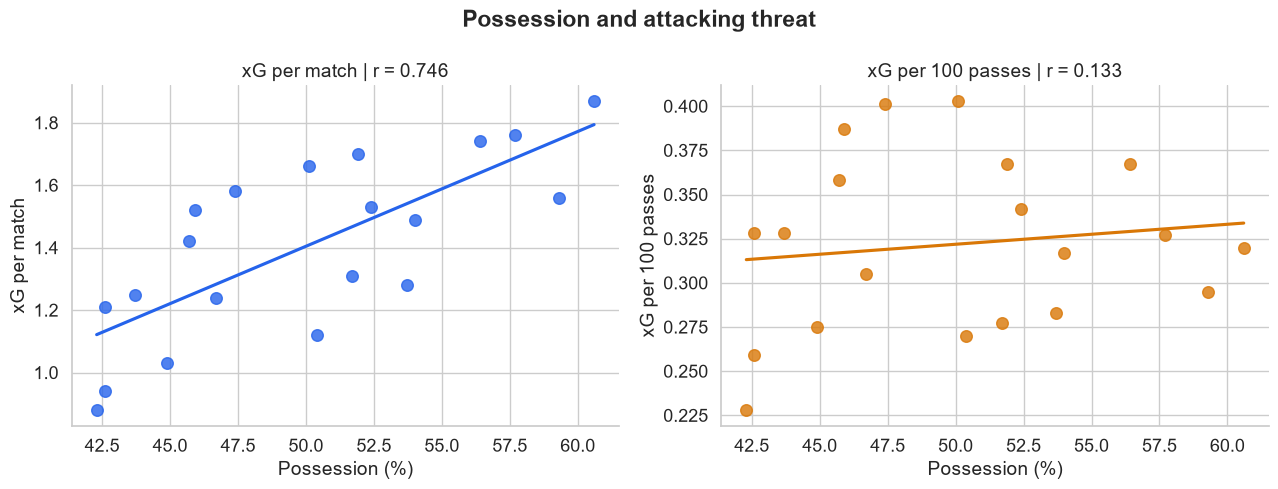

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)

sns.regplot(
    data=df, x="poss_pct", y="xg_per_match",
    ax=axes[0], ci=None, color="#2563EB",
    scatter_kws={"s": 70}
)

sns.regplot(
    data=df, x="poss_pct", y="xg_per_100_passes",
    ax=axes[1], ci=None, color="#D97706",
    scatter_kws={"s": 70}
)

axes[0].set_title("xG per match | r = " + format(r1, ".3f"))
axes[1].set_title("xG per 100 passes | r = " + format(r2, ".3f"))

axes[0].set_xlabel("Possession (%)")
axes[1].set_xlabel("Possession (%)")
axes[0].set_ylabel("xG per match")
axes[1].set_ylabel("xG per 100 passes")

fig.suptitle("Possession and attacking threat", fontweight="bold")
sns.despine()
plt.tight_layout()
plt.show()

In [13]:
fig.savefig("images/possession_comparison.png", dpi=200, bbox_inches="tight")

In [14]:
%pip install dataframe_image

   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---------------------------------------  6.6/6.7 MB 40.1 MB/s eta 0:00:01
   ---------------------------------------- 6.7/6.7 MB 33.0 MB/s  0:00:00
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 1.3/1.3 MB 49.2 MB/s  0:00:00
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ---------------------------------------- 4.1/4.1 MB 47.6 MB/s  0:00:00
   ---------------------------------------- 0.0/38.8 MB ? eta -:--:--
   --------------- ------------------------ 14.7/38.8 MB 71.8 MB/s eta 0:00:01
   ---------------------------------- ----- 33.6/38.8 MB 80.3 MB/s eta 0:00:01
   ---------------------------------------  38.8/38.8 MB 80.4 MB/s eta 0:00:01
   ---------------------------------------- 38.8/38.8 MB 55.4 MB/s  0:00:00

   ----------------------------------------  0/17 [pyee]
   ---- -----------------------------------  2/17 [mu


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import dataframe_image as dfi

table = top5_xg.style.format(precision=3).background_gradient(subset=["xg_per_match"], cmap="Blues")

await dfi.export_async(table, "images/top5_xg_per_match.png", table_conversion="matplotlib")

In [17]:
table = top5_passes.style.format(precision=3).background_gradient(subset=["xg_per_100_passes"], cmap="Blues")

await dfi.export_async(table, "images/top5_xg_per_100_passes.png", table_conversion="matplotlib")

In [ ]:
qq